# Лабораторная работа №2. Линейная и логистическая регрессия

## Цель работы

Сравнить библиотечные и собственные реализации логистической регрессии
для покупки страховки и линейной регрессии для цены ноутбука.
Для каждой задачи исследуются исходная модель и вариант после подбора
параметров и проверки дополнительных признаков.

## Данные и метрики

Используются те же данные и разбиения, что и в ЛР1:

- [Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data): по характеристикам клиента предсказывается покупка страховки. Целевая переменная — TravelInsurance. Прогноз может помочь выбрать клиентов для предложения полиса.
- [Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices): по характеристикам ноутбука оценивается его цена в евро. Целевая переменная — Price_euros. Цены взяты из исходного набора и могут отличаться от нынешних цен магазинов.

Основная метрика классификации — macro-F1: она даёт одинаковый вес
качеству распознавания двух классов. Для регрессии используется MAE,
поскольку она показывает среднюю абсолютную ошибку в евро.
Дополнительно рассчитываются Accuracy и ROC-AUC, а также RMSE и R².

Параметры подбираются на групповой кросс-валидации внутри train.
После выбора вариантов проводится оценка на отдельном тесте.

## Проверка окружения

В начале сохраняются версии библиотек и задаётся random_state=42.

In [1]:
# Проверяем окружение для линейных моделей.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedGroupKFold, GroupShuffleSplit, GroupKFold, cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## Загрузка данных

Используются исходные CSV из ЛР1. Перед чтением проверяются их контрольные
суммы: файлы и порядок строк должны совпадать с первым исследованием.

In [2]:
# Загружаем два исходных CSV.
from google.colab import files

uploaded = files.upload()

Saving laptop_prices.csv to laptop_prices.csv
Saving TravelInsurancePrediction.csv to TravelInsurancePrediction.csv


In [3]:
# Проверяем версии исходных файлов и читаем таблицы.
source_hashes = {
    "TravelInsurancePrediction.csv": "26c79f34d14138771983be3dc2dbf019c6e8b20d78db9109261149dec63da426",
    "laptop_prices.csv": "3638d6dc2c50b89263c99b364173a1f773e0b1fb0b83aa080749e95b7a77da8d"
}

for filename, expected_hash in source_hashes.items():
    actual_hash = hashlib.sha256(Path(filename).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, (
        f"Файл {filename} отличается от использованного в ЛР1."
    )

travel = pd.read_csv("TravelInsurancePrediction.csv")
laptops = pd.read_csv("laptop_prices.csv")

# Проверяем и исключаем служебный индекс.
assert np.array_equal(travel["Unnamed: 0"].to_numpy(), np.arange(len(travel)))
travel = travel.drop(columns="Unnamed: 0")

print("Страховка:", travel.shape)
print("Ноутбуки:", laptops.shape)
print("Пропуски:", travel.isna().sum().sum(), laptops.isna().sum().sum())

Страховка: (1987, 9)
Ноутбуки: (1275, 23)
Пропуски: 0 0


## Разбиения из ЛР1

Строки с одинаковыми входными признаками объединены в группы. Одна группа
целиком попадает в train или test; это позволяет проверить прогнозы на
новых сочетаниях характеристик. Целевая переменная в группы не входит.

Для страховки используется первая часть StratifiedGroupKFold из пяти,
для ноутбуков — GroupShuffleSplit с 20% групп в тесте. Настройки и seed
сохранены из ЛР1. Результат разделения и три части CV проверяются по
контрольным суммам распределения строк. Ноутбук запускается отдельно от ЛР1.

Набор входных столбцов также сохранён. Для ноутбуков исключены Product,
CPU_model и GPU_model, чтобы ограничить число редких категорий.

In [4]:
# Восстанавливаем признаки и разбиения по протоколу ЛР1.
classification_features = [
    "Age",
    "Employment Type",
    "GraduateOrNot",
    "AnnualIncome",
    "FamilyMembers",
    "ChronicDiseases",
    "FrequentFlyer",
    "EverTravelledAbroad"
]
regression_features = [
    "Company",
    "TypeName",
    "Inches",
    "Ram",
    "OS",
    "Weight",
    "Screen",
    "ScreenW",
    "ScreenH",
    "Touchscreen",
    "IPSpanel",
    "RetinaDisplay",
    "CPU_company",
    "CPU_freq",
    "PrimaryStorage",
    "SecondaryStorage",
    "PrimaryStorageType",
    "SecondaryStorageType",
    "GPU_company"
]
expected_protocol = {
    "travel": {
        "test_mask_sha256": "26baec97124eb0502e188b8451b25f110001b8c5d7c7ef7e0391b2982f09e97d",
        "cv_assignment_sha256": "96aebde84f18d8298cb2013035e3499b7c42e5103e5b95d8b337f7afb125d321"
    },
    "laptops": {
        "test_mask_sha256": "88fed4bc26da4cdd5bf8d6edb965a0e27322070907a2b50ab0017abc9cb97b3d",
        "cv_assignment_sha256": "68661b03ff5b016ab29e97c79596e6f67bedd74821bd782b3b9943f27edb7f45"
    }
}

X_cls = travel[classification_features].copy()
y_cls = travel["TravelInsurance"].copy()
X_reg = laptops[regression_features].copy()
y_reg = laptops["Price_euros"].copy()

groups_cls = pd.factorize(pd.MultiIndex.from_frame(X_cls))[0]
groups_reg = pd.factorize(pd.MultiIndex.from_frame(X_reg))[0]

split_cls = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE,
)
train_idx_cls, test_idx_cls = next(split_cls.split(X_cls, y_cls, groups_cls))
split_reg = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE,
)
train_idx_reg, test_idx_reg = next(split_reg.split(X_reg, y_reg, groups_reg))

X_train_cls, X_test_cls = X_cls.iloc[train_idx_cls].copy(), X_cls.iloc[test_idx_cls].copy()
y_train_cls, y_test_cls = y_cls.iloc[train_idx_cls].copy(), y_cls.iloc[test_idx_cls].copy()
X_train_reg, X_test_reg = X_reg.iloc[train_idx_reg].copy(), X_reg.iloc[test_idx_reg].copy()
y_train_reg, y_test_reg = y_reg.iloc[train_idx_reg].copy(), y_reg.iloc[test_idx_reg].copy()
groups_train_cls = groups_cls[train_idx_cls]
groups_train_reg = groups_reg[train_idx_reg]

cv_cls = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)
cv_reg = GroupKFold(n_splits=3)
cv_folds_cls = list(cv_cls.split(X_train_cls, y_train_cls, groups_train_cls))
cv_folds_reg = list(cv_reg.split(X_train_reg, y_train_reg, groups_train_reg))

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Проверяем номера строк test и распределение train по частям CV.
for name, X, groups, train_idx, test_idx, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    mask = np.zeros(len(X), dtype=int)
    mask[test_idx] = 1
    assert text_hash("".join(map(str, mask))) == expected_protocol[name]["test_mask_sha256"]
    assert not (set(groups[train_idx]) & set(groups[test_idx]))

    codes = np.full(len(X), "-", dtype="<U1")
    for fold_number, (fit_positions, valid_positions) in enumerate(folds):
        assert not (
            set(groups[train_idx[fit_positions]])
            & set(groups[train_idx[valid_positions]])
        )
        codes[train_idx[valid_positions]] = str(fold_number)
    assert text_hash("".join(codes)) == expected_protocol[name]["cv_assignment_sha256"]
    print(f"{name}: train={len(train_idx)}, test={len(test_idx)}; разбиения совпали с ЛР1")

travel: train=1543, test=444; разбиения совпали с ЛР1
laptops: train=1009, test=266; разбиения совпали с ЛР1


## Исходные библиотечные модели

Для страховки используется LogisticRegression с C=1 и L2-регуляризацией.
Для цены ноутбука — обычная LinearRegression, которая минимизирует сумму
квадратов ошибок.

С ними сравниваются DummyClassifier, предсказывающий наиболее частый класс,
и DummyRegressor, предсказывающий медиану обучающих цен.

Числовые признаки обрабатываются StandardScaler, категории — one-hot.
Масштабирование включено в исходную подготовку линейных моделей.
Предел итераций LogisticRegression увеличен до 3000 для сходимости.
Предобработка обучается внутри Pipeline отдельно в каждой части CV.

In [5]:
# Оцениваем исходные линейные модели на фиксированных частях CV.
def make_linear_preprocessor(X):
    numeric_columns = X.select_dtypes(include="number").columns.tolist()
    categorical_columns = [c for c in X.columns if c not in numeric_columns]
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False,
        ), categorical_columns),
    ])

def evaluate_linear_models(models, X, y, folds, scoring):
    rows = []
    for name, model in models.items():
        pipeline = Pipeline([
            ("preprocessor", make_linear_preprocessor(X)),
            ("model", model),
        ])
        scores = cross_validate(
            pipeline, X, y, cv=folds, scoring=scoring,
            n_jobs=-1, error_score="raise",
        )
        row = {"model": name}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)

scoring_cls = {"macro_f1": "f1_macro", "accuracy": "accuracy", "roc_auc": "roc_auc"}
scoring_reg = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

baseline_cv_cls = evaluate_linear_models(
    {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression baseline": LogisticRegression(
            C=1.0, max_iter=3000, random_state=RANDOM_STATE,
        ),
    },
    X_train_cls, y_train_cls, cv_folds_cls, scoring_cls,
)
baseline_cv_reg = evaluate_linear_models(
    {
        "Dummy": DummyRegressor(strategy="median"),
        "LinearRegression baseline": LinearRegression(),
    },
    X_train_reg, y_train_reg, cv_folds_reg, scoring_reg,
)

results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)
baseline_cv_cls.to_csv(results_dir / "lab2_baseline_cv_classification.csv", index=False)
baseline_cv_reg.to_csv(results_dir / "lab2_baseline_cv_regression.csv", index=False)

print("Классификация: исходные модели на CV")
display(baseline_cv_cls.round(4))
print("Регрессия: исходные модели на CV")
display(baseline_cv_reg.round(4))

Классификация: исходные модели на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,LogisticRegression baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389


Регрессия: исходные модели на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,LinearRegression baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978


### Результаты исходных моделей

На CV логистическая регрессия получила macro-F1 = 0.7164,
а линейная регрессия — MAE = 255.79 евро. Обе модели лучше Dummy:
у него macro-F1 = 0.3893 и MAE = 528.92 евро соответственно.

## Подбор регуляризации и весов классов

Первая гипотеза — изменение силы регуляризации может улучшить качество
на новых данных. Для классификации проверяются пять значений C и два
варианта весов классов: обычные и balanced. Меньшее C задаёт более сильную
регуляризацию. Вариант выбирается по среднему macro-F1.

Для регрессии сравниваются LinearRegression и Ridge при шести значениях
alpha. У Ridge большее alpha означает больший штраф на коэффициенты.
Вариант выбирается по MAE. Признаки, предобработка и части CV не меняются.

In [6]:
"""Подбор регуляризации линейных моделей на групповой CV."""

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV


def make_linear_pipeline(X, model):
    return Pipeline([
        ("preprocessor", make_linear_preprocessor(X)),
        ("model", model),
    ])


# Для классификации проверяем силу регуляризации и веса классов.
search_cls = GridSearchCV(
    estimator=make_linear_pipeline(
        X_train_cls,
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    ),
    param_grid={
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    scoring=scoring_cls,
    refit="macro_f1",
    cv=cv_folds_cls,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_cls.fit(X_train_cls, y_train_cls)

# Обычная линейная регрессия остаётся одним из кандидатов.
# У Ridge alpha задаёт силу штрафа на коэффициенты.
search_reg = GridSearchCV(
    estimator=make_linear_pipeline(X_train_reg, LinearRegression()),
    param_grid=[
        {"model": [LinearRegression()]},
        {
            "model": [Ridge(solver="svd")],
            "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
        },
    ],
    scoring=scoring_reg,
    refit="mae",
    cv=cv_folds_reg,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_reg.fit(X_train_reg, y_train_reg)


def selected_cv_summary(search, name, scoring):
    """Сводка выбранного варианта с тем же ddof=1, что у бейзлайна."""
    index = search.best_index_
    row = {"model": name}
    for metric, scorer in scoring.items():
        values = np.array([
            search.cv_results_[f"split{fold}_test_{metric}"][index]
            for fold in range(search.n_splits_)
        ])
        if scorer.startswith("neg_"):
            values = -values
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    return pd.DataFrame([row])


tuned_cv_cls = selected_cv_summary(
    search_cls, "LogisticRegression tuned", scoring_cls,
)
selected_reg_name = type(search_reg.best_estimator_.named_steps["model"]).__name__
tuned_cv_reg = selected_cv_summary(
    search_reg, selected_reg_name + " selected", scoring_reg,
)

regularization_cv_cls = pd.concat(
    [baseline_cv_cls, tuned_cv_cls], ignore_index=True,
)
regularization_cv_reg = pd.concat(
    [baseline_cv_reg, tuned_cv_reg], ignore_index=True,
)

# Сохраняем полные таблицы поиска и сравнение с исходными моделями.
pd.DataFrame(search_cls.cv_results_).to_csv(
    results_dir / "lab2_grid_classification.csv", index=False,
)
pd.DataFrame(search_reg.cv_results_).to_csv(
    results_dir / "lab2_grid_regression.csv", index=False,
)
regularization_cv_cls.to_csv(
    results_dir / "lab2_regularization_cv_classification.csv", index=False,
)
regularization_cv_reg.to_csv(
    results_dir / "lab2_regularization_cv_regression.csv", index=False,
)

print("Классификация: выбранные параметры", search_cls.best_params_)
display(regularization_cv_cls.round(4))
print("Регрессия: выбранные параметры", search_reg.best_params_)
display(regularization_cv_reg.round(4))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 7 candidates, totalling 21 fits
Классификация: выбранные параметры {'model__C': 0.01, 'model__class_weight': None}


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,LogisticRegression baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389
2,LogisticRegression tuned,0.7310,0.0331,0.7824,0.0268,0.7588,0.0331


Регрессия: выбранные параметры {'model': Ridge(solver='svd'), 'model__alpha': 1.0}


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,LinearRegression baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978
2,Ridge selected,245.9725,4.7938,343.1978,12.3575,0.7620,0.0282


### Результаты подбора регуляризации

Для классификации выбран C=0.01 без балансировки классов.
Средний macro-F1 на CV вырос с 0.7164 до 0.7310.
Для регрессии выбран Ridge с alpha=1: MAE снизилась с 255.79
до 245.97 евро, примерно на 3.8%.

## Дополнительные гипотезы

Для классификации проверяется доход на члена семьи —
AnnualIncome / FamilyMembers. Он может лучше описывать возможность покупки,
чем общий доход семьи.

Для регрессии проверяются плотность пикселей экрана PPI,
обучение на log1p цены и сочетание двух изменений.
PPI рассчитывается как sqrt(ScreenW² + ScreenH²) / Inches.

Изменения оцениваются при выбранных C и alpha на тех же частях CV.
Для моделей с логарифмом цели прогноз возвращается в евро через expm1
перед расчётом метрик.

In [7]:
"""Проверка новых признаков и логарифма цены на прежних частях CV."""

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor


def add_income_per_family(X):
    """Рассчитываем доход на члена семьи из входных характеристик."""
    result = X.copy()
    assert (result["FamilyMembers"] > 0).all(), "Проверьте размер семьи."
    result["IncomePerFamilyMember"] = (
        result["AnnualIncome"] / result["FamilyMembers"]
    )
    return result


def add_screen_density(X):
    """Добавляем плотность пикселей по диагонали и разрешению экрана."""
    result = X.copy()
    assert (result["Inches"] > 0).all(), "Проверьте диагонали экранов."
    result["PPI"] = np.sqrt(
        result["ScreenW"] ** 2 + result["ScreenH"] ** 2
    ) / result["Inches"]
    return result


# Формулы не используют целевые значения и не обучаются на данных.
X_train_cls_income = add_income_per_family(X_train_cls)
X_train_reg_ppi = add_screen_density(X_train_reg)

tuned_logistic_model = clone(search_cls.best_estimator_.named_steps["model"])
tuned_regression_model = clone(search_reg.best_estimator_.named_steps["model"])

# Сравниваем выбранную логистическую регрессию с добавлением одного признака.
income_cv_cls = evaluate_linear_models(
    {"LogisticRegression + income per family": clone(tuned_logistic_model)},
    X_train_cls_income,
    y_train_cls,
    cv_folds_cls,
    scoring_cls,
)
features_cv_cls = pd.concat(
    [tuned_cv_cls, income_cv_cls], ignore_index=True,
)

# После обучения на log1p(y) прогнозы возвращаются в евро через expm1.
assert (y_train_reg > 0).all(), "Проверьте значения цены."
log_regression_model = TransformedTargetRegressor(
    regressor=clone(tuned_regression_model),
    func=np.log1p,
    inverse_func=np.expm1,
)

regression_feature_variants = {
    "Selected regression + PPI": (
        X_train_reg_ppi, clone(tuned_regression_model),
    ),
    "Selected regression + log price": (
        X_train_reg, clone(log_regression_model),
    ),
    "Selected regression + PPI + log price": (
        X_train_reg_ppi, clone(log_regression_model),
    ),
}
regression_feature_results = [tuned_cv_reg]
for name, (X_variant, model_variant) in regression_feature_variants.items():
    result = evaluate_linear_models(
        {name: model_variant}, X_variant, y_train_reg,
        cv_folds_reg, scoring_reg,
    )
    regression_feature_results.append(result)

features_cv_reg = pd.concat(regression_feature_results, ignore_index=True)

# Сохраняем результаты без округления.
features_cv_cls.to_csv(
    results_dir / "lab2_features_cv_classification.csv", index=False,
)
features_cv_reg.to_csv(
    results_dir / "lab2_features_cv_regression.csv", index=False,
)

print("Классификация: доход на члена семьи")
display(features_cv_cls.round(4))
print("Регрессия: PPI и логарифм цены")
display(features_cv_reg.sort_values("mae_mean").round(4))


Классификация: доход на члена семьи


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,LogisticRegression tuned,0.7310,0.0331,0.7824,0.0268,0.7588,0.0331
1,LogisticRegression + income per family,0.7295,0.0325,0.7805,0.0242,0.7594,0.0307


Регрессия: PPI и логарифм цены


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
2,Selected regression + log price,240.7675,7.7107,355.3913,3.2665,0.7456,0.0110
3,Selected regression + PPI + log price,240.9131,7.0543,358.3191,8.0849,0.7416,0.0022
0,Ridge selected,245.9725,4.7938,343.1978,12.3575,0.7620,0.0282
1,Selected regression + PPI,246.0371,5.3081,342.7888,12.5702,0.7625,0.0286


### Выводы по дополнительным гипотезам

Доход на члена семьи не помог классификации: macro-F1 снизился с 0.7310
до 0.7295. Признак не включён в выбранную модель.

Наименьшая MAE регрессии получена у Ridge с логарифмом цены:
240.77 евро против 245.97 евро без преобразования. При этом RMSE выросла
с 343.20 до 355.39 евро. Вариант выбран по основной метрике MAE,
а ухудшение RMSE сохранено в сравнении. Добавление PPI не уменьшило MAE
ни у Ridge, ни у варианта с логарифмом цены.

## Собственные реализации

Линейная регрессия и Ridge реализованы через NumPy с использованием SVD.
При alpha=0 решается задача наименьших квадратов, при alpha>0 добавляется
штраф alpha * ||w||². Свободный член рассчитывается после центрирования
и не штрафуется. SVD позволяет получить решение и при зависимых столбцах.

В логистической регрессии вероятность рассчитывается через сигмоиду.
Минимизируется сумма log-loss и L2-штрафа ||w||² / (2*C), без штрафа
на свободный член. Градиент и матрица вторых производных вычисляются
в коде; параметры обновляются методом Ньютона с уменьшением шага.

Вычисления выполняются через NumPy. Из sklearn используются интерфейсы
моделей и проверки входных данных.

In [8]:
"""Линейная регрессия, Ridge и бинарная логистическая регрессия на NumPy."""

import warnings
from numbers import Integral

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y


def _predict_array(model, X):
    """Проверяем входы перед расчётом прогноза."""
    check_is_fitted(model, ["coef_", "intercept_", "n_features_in_"])
    X = check_array(X, dtype=np.float64)
    if X.shape[1] != model.n_features_in_:
        raise ValueError("Число признаков отличается от обучающей выборки.")
    return X


class MyLinearRegression(RegressorMixin, BaseEstimator):
    """МНК при alpha=0, Ridge при alpha>0. Решение через SVD."""

    def __init__(self, alpha=0.0, fit_intercept=True):
        self.alpha = alpha
        self.fit_intercept = fit_intercept

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float64, y_numeric=True)
        alpha = float(self.alpha)
        if not np.isfinite(alpha) or alpha < 0:
            raise ValueError("alpha должна быть конечной и неотрицательной.")

        # Центрирование позволяет вычислить свободный член без штрафа на него.
        X_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(X.shape[1])
        y_mean = float(y.mean()) if self.fit_intercept else 0.0
        centered_X = X - X_mean
        centered_y = y - y_mean

        U, singular_values, Vt = np.linalg.svd(centered_X, full_matrices=False)
        if alpha == 0:
            # Для вырожденных матриц используем псевдообратное решение.
            cutoff = max(centered_X.shape) * np.finfo(float).eps * singular_values[0]
            factors = np.zeros_like(singular_values)
            np.divide(
                1.0, singular_values, out=factors,
                where=singular_values > cutoff,
            )
        else:
            factors = singular_values / (singular_values ** 2 + alpha)

        self.coef_ = Vt.T @ (factors * (U.T @ centered_y))
        self.intercept_ = float(y_mean - X_mean @ self.coef_)
        self.n_features_in_ = X.shape[1]
        self.singular_ = singular_values
        return self

    def predict(self, X):
        X = _predict_array(self, X)
        return X @ self.coef_ + self.intercept_


def _sigmoid(scores):
    """Считаем сигмоиду без переполнения exp на больших числах."""
    result = np.empty_like(scores, dtype=float)
    positive = scores >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-scores[positive]))
    exp_scores = np.exp(scores[~positive])
    result[~positive] = exp_scores / (1.0 + exp_scores)
    return result


def _logistic_loss(design, target, weights, beta, penalty):
    scores = design @ beta
    losses = np.logaddexp(0.0, scores) - target * scores
    return float(weights @ losses + 0.5 * np.sum(penalty * beta ** 2))


class MyLogisticRegression(ClassifierMixin, BaseEstimator):
    """Бинарная логистическая регрессия с L2 и методом Ньютона.

    Минимизируется сумма взвешенных log-loss + ||w||² / (2*C).
    Свободный член не штрафуется. Веса классов: None или balanced.
    """

    def __init__(self, C=1.0, class_weight=None, max_iter=200,
                 tol=1e-8, fit_intercept=True):
        self.C = C
        self.class_weight = class_weight
        self.max_iter = max_iter
        self.tol = tol
        self.fit_intercept = fit_intercept

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float64)
        check_classification_targets(y)
        C = float(self.C)
        if not np.isfinite(C) or C <= 0:
            raise ValueError("C должна быть конечной и положительной.")
        if isinstance(self.max_iter, bool) or not isinstance(self.max_iter, Integral) or self.max_iter < 1:
            raise ValueError("max_iter должна быть положительным целым числом.")
        if not np.isfinite(self.tol) or self.tol <= 0:
            raise ValueError("tol должна быть конечной и положительной.")
        if self.class_weight not in (None, "balanced"):
            raise ValueError("Поддерживаются class_weight=None или balanced.")

        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("Реализация рассчитана на два класса.")
        target = encoded.astype(float)
        weights = np.ones(len(X), dtype=float)
        if self.class_weight == "balanced":
            counts = np.bincount(encoded)
            weights = len(X) / (2.0 * counts[encoded])

        design = np.column_stack([X, np.ones(len(X))]) if self.fit_intercept else X
        beta = np.zeros(design.shape[1])
        penalty = np.full(design.shape[1], 1.0 / C)
        if self.fit_intercept:
            penalty[-1] = 0.0

        loss = _logistic_loss(design, target, weights, beta, penalty)
        self.loss_history_ = [loss]
        self.n_iter_ = 0

        for _ in range(self.max_iter):
            probabilities = _sigmoid(design @ beta)
            gradient = design.T @ (weights * (probabilities - target)) + penalty * beta
            if np.max(np.abs(gradient)) / weights.sum() <= self.tol:
                break

            curvature = weights * probabilities * (1.0 - probabilities)
            hessian = design.T @ (curvature[:, None] * design) + np.diag(penalty)
            try:
                direction = np.linalg.solve(hessian, gradient)
            except np.linalg.LinAlgError:
                direction = np.linalg.lstsq(hessian, gradient, rcond=None)[0]

            # При слишком большом шаге уменьшаем его до снижения функции потерь.
            step = 1.0
            directional_derivative = float(gradient @ direction)
            accepted = False
            for _ in range(40):
                candidate = beta - step * direction
                candidate_loss = _logistic_loss(design, target, weights, candidate, penalty)
                rounding_tolerance = 1e-12 * (1.0 + abs(loss))
                if candidate_loss <= loss - 1e-4 * step * directional_derivative + rounding_tolerance:
                    beta, loss = candidate, candidate_loss
                    accepted = True
                    break
                step *= 0.5

            if not accepted:
                break
            self.n_iter_ += 1
            self.loss_history_.append(loss)

        gradient = design.T @ (weights * (_sigmoid(design @ beta) - target)) + penalty * beta
        self.gradient_norm_ = float(np.max(np.abs(gradient)) / weights.sum())
        self.converged_ = self.gradient_norm_ <= self.tol
        if not self.converged_:
            warnings.warn("Метод Ньютона не достиг заданной точности.", ConvergenceWarning)

        self.n_features_in_ = X.shape[1]
        if self.fit_intercept:
            self.coef_ = beta[:-1].reshape(1, -1)
            self.intercept_ = np.array([beta[-1]])
        else:
            self.coef_ = beta.reshape(1, -1)
            self.intercept_ = np.array([0.0])
        return self

    def decision_function(self, X):
        X = _predict_array(self, X)
        return X @ self.coef_.ravel() + self.intercept_[0]

    def predict_proba(self, X):
        positive_probability = _sigmoid(self.decision_function(X))
        return np.column_stack([1.0 - positive_probability, positive_probability])

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[(scores > 0).astype(int)]


### Проверка вычислений

На небольших искусственных данных сравниваются прогнозы со sklearn.
Для линейной регрессии и Ridge проверяются разные значения alpha,
зависимые столбцы и наличие свободного члена.

Для логистической регрессии сравниваются классы и вероятности при
C=1 и C=0.01, с обычными весами и balanced. Отдельно проверяется
обратное преобразование логарифма цели для своего регрессора.

In [9]:
"""Проверки собственных линейных моделей на искусственных данных."""

from numpy.testing import assert_allclose, assert_array_equal
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge

rng = np.random.default_rng(RANDOM_STATE)
X_toy = rng.normal(size=(120, 5))
# Добавляем зависимый столбец для проверки решения вырожденной задачи.
X_toy = np.column_stack([X_toy, X_toy[:, 0] + X_toy[:, 1]])
X_queries = rng.normal(size=(20, 5))
X_queries = np.column_stack([X_queries, X_queries[:, 0] + X_queries[:, 1]])
y_toy_reg = 2.0 * X_toy[:, 0] - X_toy[:, 1] + 3.0 + rng.normal(scale=0.1, size=len(X_toy))

for alpha in [0.0, 1.0]:
    for intercept in [False, True]:
        own = MyLinearRegression(alpha=alpha, fit_intercept=intercept).fit(X_toy, y_toy_reg)
        library = (
            LinearRegression(fit_intercept=intercept) if alpha == 0
            else Ridge(alpha=alpha, fit_intercept=intercept, solver="svd")
        ).fit(X_toy, y_toy_reg)
        assert_allclose(own.predict(X_queries), library.predict(X_queries), rtol=1e-8, atol=1e-8)

print("МНК и Ridge: предсказания совпали с sklearn.")

binary_target = X_toy[:, 0] - 0.6 * X_toy[:, 1] + rng.normal(scale=0.8, size=len(X_toy)) > 0.9
y_toy_cls = np.where(binary_target, "yes", "no")

for C in [1.0, 0.01]:
    for class_weight in [None, "balanced"]:
        for intercept in [False, True]:
            own = MyLogisticRegression(C=C, class_weight=class_weight, fit_intercept=intercept).fit(X_toy, y_toy_cls)
            library = LogisticRegression(
                C=C, class_weight=class_weight, fit_intercept=intercept,
                max_iter=5000, tol=1e-10,
            ).fit(X_toy, y_toy_cls)
            assert own.converged_, "Проверьте сходимость собственной модели."
            assert_allclose(own.predict_proba(X_queries), library.predict_proba(X_queries), rtol=1e-5, atol=1e-6)
            assert_array_equal(own.predict(X_queries), library.predict(X_queries))
            assert_allclose(own.predict_proba(X_queries).sum(axis=1), 1.0)

print("Логистическая регрессия: классы и вероятности согласуются со sklearn.")

# Проверяем клонирование своего регрессора и обратное преобразование цены.
positive_target = np.exp(2.0 + 0.2 * X_toy[:, 0])
own_log = TransformedTargetRegressor(
    regressor=MyLinearRegression(alpha=1.0), func=np.log1p, inverse_func=np.expm1,
).fit(X_toy, positive_target)
library_log = TransformedTargetRegressor(
    regressor=Ridge(alpha=1.0, solver="svd"), func=np.log1p, inverse_func=np.expm1,
).fit(X_toy, positive_target)
assert_allclose(own_log.predict(X_queries), library_log.predict(X_queries), rtol=1e-8, atol=1e-8)

print("Ridge с логарифмом цели: проверка пройдена.")


МНК и Ridge: предсказания совпали с sklearn.
Логистическая регрессия: классы и вероятности согласуются со sklearn.
Ridge с логарифмом цели: проверка пройдена.


## Сравнение четырёх вариантов на CV

В каждой задаче сравниваются библиотечная и собственная модели
с исходными настройками и с настройками, выбранными по CV.

Для классификации исходный вариант использует C=1, выбранный — C=0.01.
В обоих случаях class_weight=None.
Для регрессии исходный вариант — обычная линейная регрессия,
выбранный — Ridge с alpha=1 и log1p/expm1 цены.

У соответствующих моделей одинаковые признаки, StandardScaler,
one-hot и части CV. Доход на члена семьи и PPI не добавляются.
У собственного классификатора также проверяется сходимость на каждом train.

В таблицах baseline обозначает исходный вариант, improved — вариант,
выбранный по CV. Его качество на тесте оценивается следующим этапом.

In [10]:
"""Сравнение четырёх вариантов линейных моделей на групповой CV."""

from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge


# Фиксируем выбранные настройки до финальной оценки на test.
IMPROVED_C = 0.01
IMPROVED_ALPHA = 1.0
assert search_cls.best_params_["model__C"] == IMPROVED_C
assert search_cls.best_params_["model__class_weight"] is None
assert isinstance(search_reg.best_estimator_.named_steps["model"], Ridge)
assert search_reg.best_estimator_.named_steps["model"].alpha == IMPROVED_ALPHA

cv_models_cls = {
    "sklearn baseline": LogisticRegression(
        C=1.0, max_iter=3000, random_state=RANDOM_STATE,
    ),
    "sklearn improved": LogisticRegression(
        C=IMPROVED_C, max_iter=3000, random_state=RANDOM_STATE,
    ),
    "own baseline": MyLogisticRegression(C=1.0),
    "own improved": MyLogisticRegression(C=IMPROVED_C),
}

cv_models_reg = {
    "sklearn baseline": LinearRegression(),
    "sklearn improved": TransformedTargetRegressor(
        regressor=Ridge(alpha=IMPROVED_ALPHA, solver="svd"),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "own baseline": MyLinearRegression(alpha=0.0),
    "own improved": TransformedTargetRegressor(
        regressor=MyLinearRegression(alpha=IMPROVED_ALPHA),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}


def compare_linear_variants(models, X, y, folds, scoring, task):
    """Считаем метрики и сохраняем результаты каждой части CV."""
    summary_rows = []
    fold_rows = []

    for name, model in models.items():
        pipeline = make_linear_pipeline(X, model)
        scores = cross_validate(
            pipeline, X, y,
            cv=folds,
            scoring=scoring,
            n_jobs=-1,
            return_estimator=True,
            error_score="raise",
        )

        metric_values = {}
        row = {"model": name}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            metric_values[metric] = values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        summary_rows.append(row)

        for fold, fitted_pipeline in enumerate(scores["estimator"]):
            fitted_model = fitted_pipeline.named_steps["model"]
            fold_row = {
                "task": task,
                "model": name,
                "validation_fold": fold,
            }
            for metric, values in metric_values.items():
                fold_row[metric] = values[fold]

            # Проверяем завершение метода Ньютона в каждой части CV.
            if hasattr(fitted_model, "converged_"):
                assert fitted_model.converged_, (
                    f"Нет сходимости: {name}, часть {fold}."
                )
                fold_row["converged"] = fitted_model.converged_
                fold_row["iterations"] = fitted_model.n_iter_
                fold_row["gradient_norm"] = fitted_model.gradient_norm_
            fold_rows.append(fold_row)

    return pd.DataFrame(summary_rows), pd.DataFrame(fold_rows)


# Признаки одинаковы для соответствующих моделей; PPI и доход на члена семьи не добавляются.
cv_comparison_cls, cv_folds_results_cls = compare_linear_variants(
    cv_models_cls, X_train_cls, y_train_cls,
    cv_folds_cls, scoring_cls, "classification",
)
cv_comparison_reg, cv_folds_results_reg = compare_linear_variants(
    cv_models_reg, X_train_reg, y_train_reg,
    cv_folds_reg, scoring_reg, "regression",
)

# Сохраняем сводки и индивидуальные результаты частей CV.
for filename, table in {
    "lab2_four_variants_cv_classification.csv": cv_comparison_cls,
    "lab2_four_variants_cv_regression.csv": cv_comparison_reg,
    "lab2_cv_folds_classification.csv": cv_folds_results_cls,
    "lab2_cv_folds_regression.csv": cv_folds_results_reg,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Классификация: четыре варианта на CV")
display(cv_comparison_cls.round(4))
print("Регрессия: четыре варианта на CV")
display(cv_comparison_reg.round(4))
print("Сходимость собственной логистической регрессии:")
display(cv_folds_results_cls.loc[
    cv_folds_results_cls["model"].str.startswith("own"),
    ["model", "validation_fold", "converged", "iterations", "gradient_norm"],
])


Классификация: четыре варианта на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,sklearn baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389
1,sklearn improved,0.7310,0.0331,0.7824,0.0268,0.7588,0.0331
2,own baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389
3,own improved,0.7310,0.0331,0.7824,0.0268,0.7587,0.0332


Регрессия: четыре варианта на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,sklearn baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978
1,sklearn improved,240.7675,7.7107,355.3913,3.2665,0.7456,0.0110
2,own baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978
3,own improved,240.7675,7.7107,355.3913,3.2665,0.7456,0.0110


Сходимость собственной логистической регрессии:


,model,validation_fold,converged,iterations,gradient_norm
6,own baseline,0,True,4.0,2.463265e-09
7,own baseline,1,True,4.0,6.566024e-09
8,own baseline,2,True,5.0,1.574422e-14
9,own improved,0,True,4.0,2.597623e-13
10,own improved,1,True,4.0,2.239934e-13
11,own improved,2,True,4.0,2.817663e-12


### Результаты сравнения на CV

Основные метрики собственных и библиотечных моделей совпали при показанном
округлении: macro-F1 выбранной классификации — 0.7310,
MAE выбранной регрессии — 240.77 евро.
Небольшое различие осталось в ROC-AUC классификации.
Метод Ньютона сошёлся на всех частях CV за 4–5 шагов.

## Финальная оценка на тесте

Зафиксированные варианты обучаются на полном train и оцениваются
на сохранённой тестовой части. Рассчитываются те же метрики качества,
а для покупателей страховки дополнительно — Precision и Recall.

Время обучения и предсказания измеряется вместе с предобработкой.
Это время одного запуска в Colab; при повторении оно может измениться.

In [11]:
"""Финальная оценка моделей ЛР2 на отложенном тесте."""

from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)


# Модели и предобработка соответствуют сравнению четырёх вариантов на CV.
final_models_cls = {
    name: make_linear_pipeline(X_train_cls, clone(model))
    for name, model in cv_models_cls.items()
}
final_models_reg = {
    name: make_linear_pipeline(X_train_reg, clone(model))
    for name, model in cv_models_reg.items()
}


def evaluate_linear_final(models, X_train, y_train, X_test, y_test, task):
    """Обучаем зафиксированные варианты на полном train и сохраняем прогнозы."""
    metric_rows = []
    solver_rows = []
    predictions = pd.DataFrame({
        "row_position": X_test.index.to_numpy(),
        "target": y_test.to_numpy(),
    })

    for name, pipeline in models.items():
        started = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - started

        fitted_model = pipeline.named_steps["model"]
        if hasattr(fitted_model, "converged_"):
            assert fitted_model.converged_, f"Нет сходимости: {name}."
            solver_rows.append({
                "model": name,
                "converged": fitted_model.converged_,
                "iterations": fitted_model.n_iter_,
                "gradient_norm": fitted_model.gradient_norm_,
            })

        started = perf_counter()
        predicted = pipeline.predict(X_test)
        predict_seconds = perf_counter() - started
        predictions[name] = predicted
        row = {
            "model": name,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
        }

        if task == "classification":
            started = perf_counter()
            positive_column = list(pipeline.classes_).index(1)
            probabilities = pipeline.predict_proba(X_test)[:, positive_column]
            row["predict_proba_seconds"] = perf_counter() - started
            predictions[f"{name} probability_1"] = probabilities
            row.update({
                "macro_f1": f1_score(y_test, predicted, average="macro"),
                "accuracy": accuracy_score(y_test, predicted),
                "roc_auc": roc_auc_score(y_test, probabilities),
                "precision_1": precision_score(y_test, predicted, zero_division=0),
                "recall_1": recall_score(y_test, predicted, zero_division=0),
            })
        else:
            # Включая модели с логарифмом цели: predict возвращает цену в евро.
            row.update({
                "mae": mean_absolute_error(y_test, predicted),
                "rmse": np.sqrt(mean_squared_error(y_test, predicted)),
                "r2": r2_score(y_test, predicted),
            })
        metric_rows.append(row)

    return pd.DataFrame(metric_rows), predictions, pd.DataFrame(solver_rows)


final_test_cls, final_predictions_cls, final_solver_checks = evaluate_linear_final(
    final_models_cls, X_train_cls, y_train_cls,
    X_test_cls, y_test_cls, "classification",
)
final_test_reg, final_predictions_reg, _ = evaluate_linear_final(
    final_models_reg, X_train_reg, y_train_reg,
    X_test_reg, y_test_reg, "regression",
)

# Сохраняем полные значения, а для отображения округляем копии таблиц.
for filename, table in {
    "lab2_final_test_classification.csv": final_test_cls,
    "lab2_final_test_regression.csv": final_test_reg,
    "lab2_final_predictions_classification.csv": final_predictions_cls,
    "lab2_final_predictions_regression.csv": final_predictions_reg,
    "lab2_final_solver_checks.csv": final_solver_checks,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Финальная оценка классификации на test:")
display(final_test_cls.round(4))
print("Финальная оценка регрессии на test:")
display(final_test_reg.round(4))
print("Сходимость собственной логистической регрессии на полном train:")
display(final_solver_checks)
print("Время включает предобработку и относится к одному запуску.")
print("Время predict_proba измерено отдельно от predict.")
print("Метрики и прогнозы сохранены в:", results_dir)


Финальная оценка классификации на test:


,model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,sklearn baseline,0.0135,0.0039,0.0037,0.6999,0.7590,0.7521,0.7292,0.4636
1,sklearn improved,0.0102,0.0037,0.0036,0.7103,0.7703,0.7495,0.7692,0.4636
2,own baseline,0.0083,0.0036,0.0036,0.6999,0.7590,0.7521,0.7292,0.4636
3,own improved,0.0087,0.0036,0.0036,0.7103,0.7703,0.7494,0.7692,0.4636


Финальная оценка регрессии на test:


,model,fit_seconds,predict_seconds,mae,rmse,r2
0,sklearn baseline,0.0139,0.0055,248.6209,341.5790,0.7477
1,sklearn improved,0.0825,0.0064,264.3096,574.5573,0.2862
2,own baseline,0.0150,0.0053,248.6209,341.5790,0.7477
3,own improved,0.0140,0.0055,264.3096,574.5573,0.2862


Сходимость собственной логистической регрессии на полном train:


,model,converged,iterations,gradient_norm
0,own baseline,True,4,9.592885e-09
1,own improved,True,4,6.009299e-12


Время включает предобработку и относится к одному запуску.
Время predict_proba измерено отдельно от predict.
Метрики и прогнозы сохранены в: /content/results


### Результаты на тесте

Macro-F1 классификации вырос с 0.6999 до 0.7103.
Для регрессии результат оказался хуже исходного: MAE выросла
с 248.62 до 264.31 евро, RMSE — с 341.58 до 574.56 евро.
Уменьшение ошибки на CV не сохранилось на тестовой выборке.

Собственные и библиотечные модели получили близкие результаты.
Метод Ньютона сошёлся на полном train при обоих значениях C.

## Разбор ошибок регрессии

Проверяется, что прогнозы переведены из логарифма в евро ровно один раз
и согласуются между реализациями. Затем рассматриваются наибольшие ошибки
и их доля в сумме квадратов ошибок. Это разбор зафиксированных прогнозов;
новые параметры по тесту не выбираются.

In [12]:
"""Разбор ошибок зафиксированных регрессоров на тесте."""

# Проверяем, что сравниваем прогнозы в евро, а преобразование выполнено один раз.
selected_pipeline = final_models_reg["sklearn improved"]
transformed_test = selected_pipeline.named_steps["preprocessor"].transform(X_test_reg)
target_wrapper = selected_pipeline.named_steps["model"]
log_predictions = target_wrapper.regressor_.predict(transformed_test)
np.testing.assert_allclose(
    np.expm1(log_predictions),
    final_predictions_reg["sklearn improved"].to_numpy(),
    rtol=1e-10,
    atol=1e-8,
)

# Сравниваем прогнозы реализаций до округления таблиц.
for version in ["baseline", "improved"]:
    np.testing.assert_allclose(
        final_predictions_reg[f"own {version}"].to_numpy(),
        final_predictions_reg[f"sklearn {version}"].to_numpy(),
        rtol=1e-8,
        atol=1e-6,
    )
print("Проверки прогнозов в евро и согласованности реализаций пройдены.")

errors = final_predictions_reg[["row_position", "target"]].copy()
errors["baseline_prediction"] = final_predictions_reg["sklearn baseline"].to_numpy()
errors["selected_prediction"] = final_predictions_reg["sklearn improved"].to_numpy()
errors["baseline_abs_error"] = np.abs(errors["target"] - errors["baseline_prediction"])
errors["selected_abs_error"] = np.abs(errors["target"] - errors["selected_prediction"])
errors["selected_residual"] = errors["target"] - errors["selected_prediction"]

print("Восемь наибольших ошибок выбранного регрессора:")
display(errors.sort_values("selected_abs_error", ascending=False).head(8).round(2))

# Крупные ошибки сильнее влияют на RMSE, чем на MAE.
summary_rows = []
for name, column in [
    ("sklearn baseline", "baseline_abs_error"),
    ("sklearn improved", "selected_abs_error"),
]:
    absolute = errors[column].to_numpy()
    squared = absolute ** 2
    summary_rows.append({
        "model": name,
        "median_abs_error": np.median(absolute),
        "p90_abs_error": np.quantile(absolute, 0.9),
        "max_abs_error": absolute.max(),
        "largest_error_share_squared_pct": 100.0 * squared.max() / squared.sum(),
        "top3_errors_share_squared_pct": 100.0 * np.sort(squared)[-3:].sum() / squared.sum(),
    })
error_summary = pd.DataFrame(summary_rows)
print("Распределение ошибок:")
display(error_summary.round(2))

# Смотрим исходные характеристики нескольких объектов с наибольшими ошибками.
worst_rows = errors.sort_values("selected_abs_error", ascending=False).head(3)
details = laptops.iloc[worst_rows["row_position"].astype(int).to_numpy()][[
    "Company", "Product", "TypeName", "Ram", "CPU_freq", "Weight", "Price_euros",
]].copy()
details.insert(0, "row_position", worst_rows["row_position"].to_numpy())
details["selected_prediction"] = worst_rows["selected_prediction"].to_numpy()
print("Характеристики трёх объектов с наибольшими ошибками:")
display(details.round(2))

errors.to_csv(results_dir / "lab2_regression_error_details.csv", index=False)
error_summary.to_csv(results_dir / "lab2_regression_error_summary.csv", index=False)


Проверки прогнозов в евро и согласованности реализаций пройдены.
Восемь наибольших ошибок выбранного регрессора:


,row_position,target,baseline_prediction,selected_prediction,baseline_abs_error,selected_abs_error,selected_residual
227,1066,3975.00,4841.13,11481.44,866.13,7506.44,-7506.44
48,247,2999.00,1797.35,1548.28,1201.65,1450.72,1450.72
155,767,1099.00,2239.19,2287.14,1140.19,1188.14,-1188.14
142,707,1855.00,2816.14,3008.35,961.14,1153.35,-1153.35
238,1116,2749.99,1801.11,1610.94,948.88,1139.05,1139.05
90,438,2382.00,3033.46,3484.35,651.46,1102.35,-1102.35
66,329,2639.00,3060.10,3738.33,421.10,1099.33,-1099.33
249,1189,2599.00,1842.44,1617.67,756.56,981.33,981.33


Распределение ошибок:


,model,median_abs_error,p90_abs_error,max_abs_error,largest_error_share_squared_pct,top3_errors_share_squared_pct
0,sklearn baseline,176.14,544.24,1657.50,8.85,17.69
1,sklearn improved,146.25,585.69,7506.44,64.17,68.17


Характеристики трёх объектов с наибольшими ошибками:


,row_position,Company,Product,TypeName,Ram,CPU_freq,Weight,Price_euros,selected_prediction
1066,1066,Asus,ROG G701VO,Gaming,64,2.7,3.58,3975.0,11481.44
247,247,Asus,Rog G701VIK-BA060T,Gaming,16,2.9,3.60,2999.0,1548.28
767,767,Dell,Inspiron 7559,Gaming,16,2.6,2.72,1099.0,2287.14


## Графики ошибок и сходимость

Ниже приведены матрицы ошибок четырёх классификаторов, прогнозы и остатки
двух библиотечных регрессоров. Для собственного классификатора показано
изменение функции потерь по шагам метода Ньютона.

Дополнительно сравнивается RAM объекта с наибольшей ошибкой
с диапазоном RAM в обучающих данных.

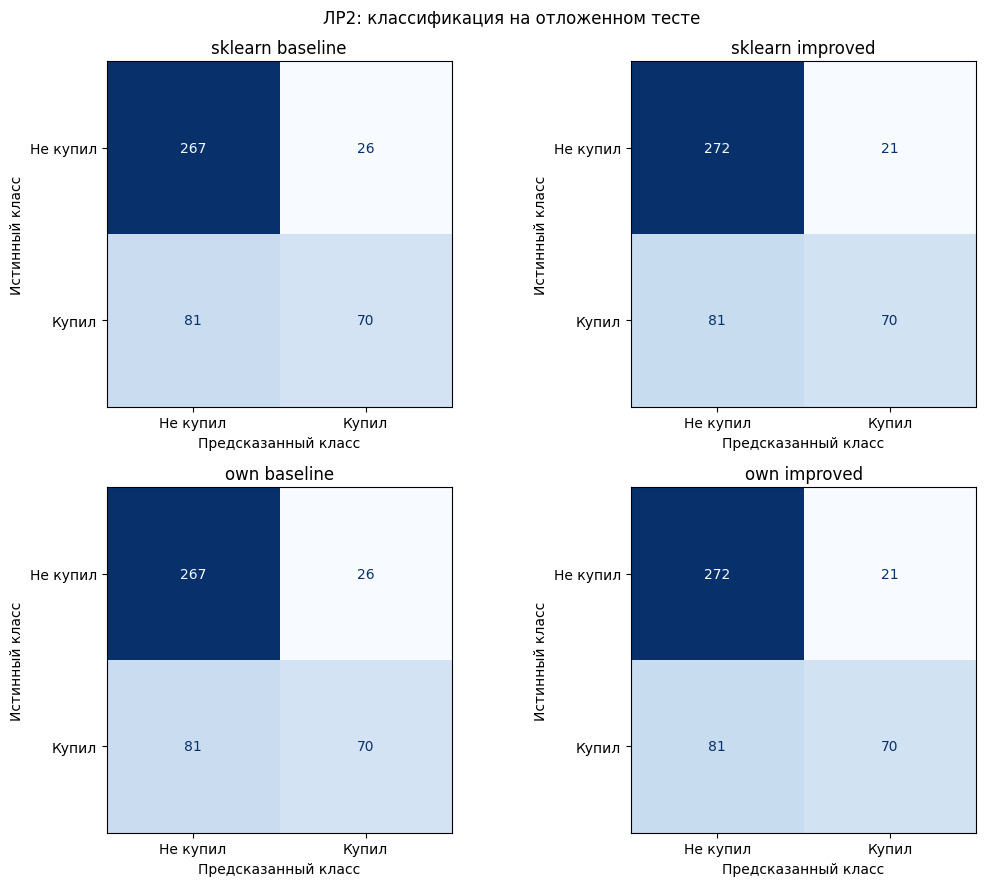

,model,tn,fp,fn,tp
0,sklearn baseline,267,26,81,70
1,sklearn improved,272,21,81,70
2,own baseline,267,26,81,70
3,own improved,272,21,81,70


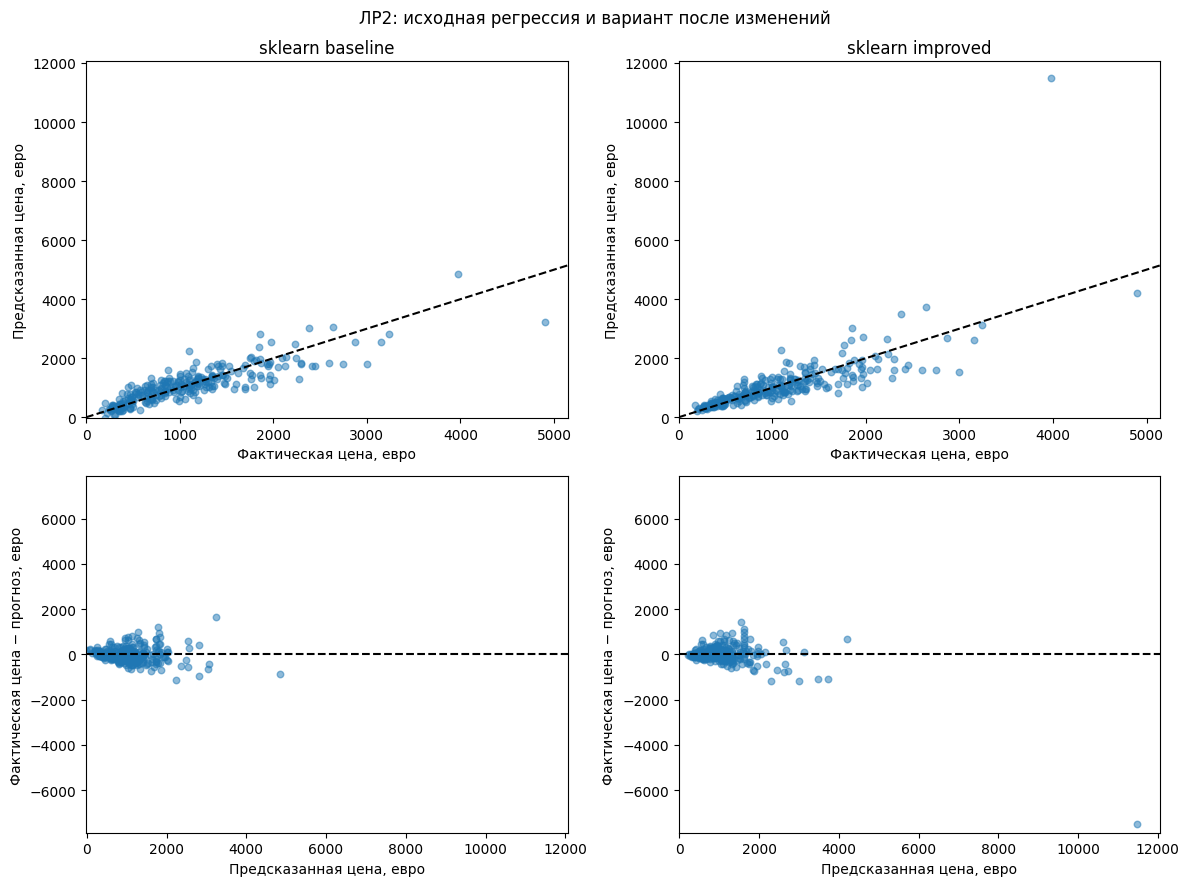

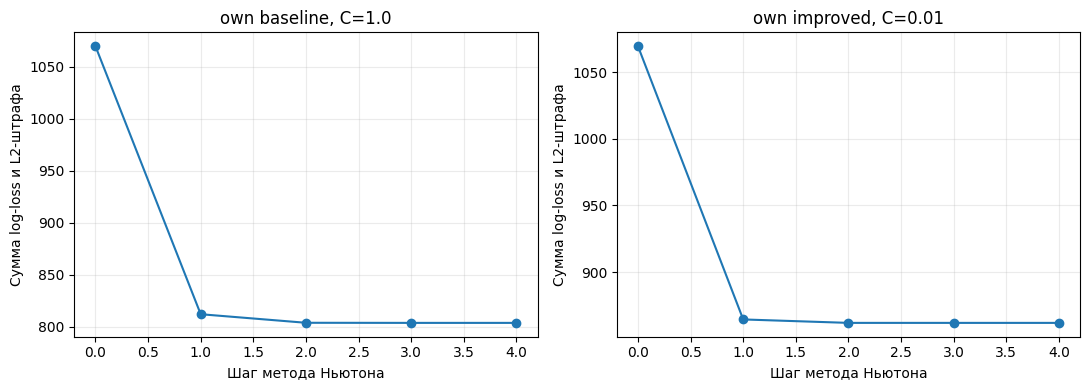

RAM объекта с наибольшей ошибкой и диапазон обучения:


,row_position,train_ram_min,train_ram_max,test_object_ram,target,prediction
0,1066,2,32,64,3975.0,11481.44


Архив результатов подготовлен: lab2_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
"""Графики ошибок, сходимость и сохранение результатов ЛР2."""

import importlib.metadata
import zipfile
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

figures_dir = results_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Матрицы ошибок четырёх классификаторов.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
confusion_rows = []
for ax, name in zip(axes.flat, final_models_cls):
    predicted = final_predictions_cls[name].to_numpy()
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls, predicted, labels=[0, 1],
        display_labels=["Не купил", "Купил"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    tn, fp, fn, tp = confusion_matrix(y_test_cls, predicted, labels=[0, 1]).ravel()
    confusion_rows.append({"model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp})

fig.suptitle("ЛР2: классификация на отложенном тесте")
fig.tight_layout()
fig.savefig(figures_dir / "lab2_confusion_matrices.png", dpi=180)
plt.show()
confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(results_dir / "lab2_confusion_counts.csv", index=False)
display(confusion_table)

# На графиках регрессии сравниваем исходную модель с выбранным по CV вариантом.
# Предсказания своей и библиотечной реализаций проверены на близость отдельно.
names = ["sklearn baseline", "sklearn improved"]
actual = y_test_reg.to_numpy()
predicted_max = max(final_predictions_reg[name].max() for name in names)
predicted_min = min(final_predictions_reg[name].min() for name in names)
upper = max(actual.max(), predicted_max) * 1.05
lower = min(0.0, predicted_min * 1.05)
residual_limit = max(
    np.abs(actual - final_predictions_reg[name].to_numpy()).max() for name in names
) * 1.05

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for column, name in enumerate(names):
    predicted = final_predictions_reg[name].to_numpy()
    ax = axes[0, column]
    ax.scatter(actual, predicted, alpha=0.5, s=22)
    ax.plot([0, upper], [0, upper], "--", color="black")
    ax.set_xlim(0, actual.max() * 1.05)
    ax.set_ylim(lower, upper)
    ax.set_title(name)
    ax.set_xlabel("Фактическая цена, евро")
    ax.set_ylabel("Предсказанная цена, евро")

    ax = axes[1, column]
    ax.scatter(predicted, actual - predicted, alpha=0.5, s=22)
    ax.axhline(0, linestyle="--", color="black")
    ax.set_xlim(lower, upper)
    ax.set_ylim(-residual_limit, residual_limit)
    ax.set_xlabel("Предсказанная цена, евро")
    ax.set_ylabel("Фактическая цена − прогноз, евро")

fig.suptitle("ЛР2: исходная регрессия и вариант после изменений")
fig.tight_layout()
fig.savefig(figures_dir / "lab2_regression_errors.png", dpi=180)
plt.show()

# Функция потерь собственного классификатора по шагам метода Ньютона.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["own baseline", "own improved"]):
    model = final_models_cls[name].named_steps["model"]
    ax.plot(np.arange(len(model.loss_history_)), model.loss_history_, marker="o")
    ax.set_title(f"{name}, C={model.C}")
    ax.set_xlabel("Шаг метода Ньютона")
    ax.set_ylabel("Сумма log-loss и L2-штрафа")
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / "lab2_newton_loss.png", dpi=180)
plt.show()

# Проверяем диапазон RAM у наблюдения с наибольшей ошибкой.
worst = errors.loc[errors["selected_abs_error"].idxmax()]
worst_position = int(worst["row_position"])
ram_check = pd.DataFrame([{
    "row_position": worst_position,
    "train_ram_min": X_train_reg["Ram"].min(),
    "train_ram_max": X_train_reg["Ram"].max(),
    "test_object_ram": X_test_reg.loc[worst_position, "Ram"],
    "target": worst["target"],
    "prediction": worst["selected_prediction"],
}])
print("RAM объекта с наибольшей ошибкой и диапазон обучения:")
display(ram_check.round(2))
ram_check.to_csv(results_dir / "lab2_ram_range_check.csv", index=False)

# Сохраняем разбиения и части CV, использованные в этой работе.
split_dir = Path("/content/data/splits")
split_dir.mkdir(parents=True, exist_ok=True)
for name, X, groups, train_idx, test_idx, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    assignment = np.full(len(X), "train", dtype=object)
    assignment[test_idx] = "test"
    pd.DataFrame({
        "row_position": np.arange(len(X)), "group_id": groups, "subset": assignment,
    }).to_csv(split_dir / f"{name}_split.csv", index=False)

    fold_assignment = np.full(len(train_idx), -1, dtype=int)
    for number, (_, valid_positions) in enumerate(folds):
        assert (fold_assignment[valid_positions] == -1).all()
        fold_assignment[valid_positions] = number
    assert (fold_assignment >= 0).all()
    pd.DataFrame({
        "row_position": train_idx, "group_id": groups[train_idx],
        "validation_fold": fold_assignment,
    }).to_csv(split_dir / f"{name}_cv.csv", index=False)

packages = {
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn"]
}
settings = {
    "lab": 2,
    "python": sys.version.split()[0],
    "random_state": RANDOM_STATE,
    "packages": packages,
    "source_sha256": source_hashes,
    "split_fingerprints": expected_protocol,
    "classification": {
        "features": classification_features,
        "baseline_C": 1.0,
        "selected_C": IMPROVED_C,
        "class_weight": None,
        "numeric_scaling": "StandardScaler",
        "selection_metric": "macro_f1",
    },
    "regression": {
        "features": regression_features,
        "baseline": "ordinary least squares",
        "selected": "Ridge with log1p/expm1 target",
        "selected_alpha": IMPROVED_ALPHA,
        "ppi": False,
        "numeric_scaling": "StandardScaler",
        "selection_metric": "mae",
    },
    "timing": "One run including preprocessing; predict_proba timed separately",
}
(results_dir / "lab2_settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8",
)

# Архив содержит результаты ЛР2; ноутбук сохраняется отдельно в формате ipynb.
archive_path = Path("/content/lab2_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(results_dir.rglob("*")):
        if path.is_file() and path.name.startswith("lab2_"):
            archive.write(path, str(Path("results") / path.relative_to(results_dir)))
    for filename in ["travel_split.csv", "laptops_split.csv", "travel_cv.csv", "laptops_cv.csv"]:
        archive.write(split_dir / filename, f"data/splits/{filename}")
    archive.writestr(
        "requirements_lab2.txt",
        "\n".join(f"{name}=={version}" for name, version in packages.items()) + "\n",
    )

print("Архив результатов подготовлен:", archive_path.name)
files.download(str(archive_path))


## Итоговые выводы

В работе исследованы логистическая регрессия для покупки страховки
и линейная регрессия для цены ноутбука. Для каждой задачи оценены
библиотечная и собственная модели до и после выбранных изменений.

В классификации уменьшение C до 0.01 улучшило macro-F1:
на CV с 0.7164 до 0.7310, на тесте с 0.6999 до 0.7103.
Ложных положительных прогнозов стало 21 вместо 26, но число найденных
покупателей осталось прежним — 70 из 151. Поэтому полнота по-прежнему
составляет около 46%. Доход на члена семьи не улучшил основную метрику
и в выбранную модель не вошёл.

Для регрессии по CV выбран Ridge с alpha=1 и логарифмом цены:
MAE снизилась с 255.79 до 240.77 евро. На тесте этот вариант оказался
хуже исходной линейной регрессии: MAE выросла с 248.62 до 264.31 евро,
RMSE — с 341.58 до 574.56 евро. PPI не дал уменьшения MAE.

Самый большой промах получен для Asus ROG G701VO: прогноз 11481.44 евро
при цене 3975 евро. На этот объект приходится 64.17% суммы квадратов ошибок
выбранного регрессора. У него 64 ГБ RAM, тогда как в train максимум 32 ГБ.
Таким образом, для одного из признаков прогноз выполнялся за пределами
обучающего диапазона.

Медианная абсолютная ошибка снизилась со 176.14 до 146.25 евро,
но крупные ошибки ухудшили MAE и RMSE. Это показывает, почему уменьшения
ошибки на CV или у типичного объекта недостаточно для вывода об общем
улучшении модели.

Собственные реализации дали близкие к sklearn результаты. Проверки
на искусственных данных прошли, метод Ньютона сошёлся на частях CV
и на полном train. Параметры выбирались по CV, а тест использовался
для финальной оценки и разбора ошибок. Время работы относится к одному
запуску с учётом предобработки.